# RouteMind Dubai: ETA / delay model (owner: Atharva, Slide 3)

**Dataset:** Kaggle "Amazon Delivery Dataset" (`sujalsuthar/amazon-delivery-dataset`), file `amazon_delivery.csv`, **MIT licence**.
43,739 deliveries, 16 columns: `Order_ID, Agent_Age, Agent_Rating, Store_Latitude, Store_Longitude, Drop_Latitude, Drop_Longitude,
Order_Date, Order_Time, Pickup_Time, Weather, Traffic, Vehicle, Area, Delivery_Time, Category`. Order dates 2022-02-11 to 2022-04-06.
Target: `Delivery_Time` (minutes).

**Caveat: the data is from Indian cities, not Dubai.** The model demonstrates the method (predict delivery time from distance,
time of day, traffic, weather, vehicle, area). It is not Dubai ground truth. DubaiDash Express is fictional; its numbers are assumed.

**Rules used here**
- No target leakage: `Pickup_Time` is dropped (only known after pickup); nothing after delivery is used.
- **Chronological split**: orders sorted by date and time; the last 20% is the test set. The last 10% of the training part is used for early stopping.
- Naive baseline: median delivery time per 2 km distance bucket (learned on the training set only).
- Model: LightGBM (gradient-boosted trees), exported as plain JSON so the browser evaluates it in TypeScript (`web/lib/models/eta.ts`).

Run locally or in Colab: `pip install pandas numpy scikit-learn lightgbm matplotlib`, put the CSV in `notebook/data/raw/`.

In [1]:
import json, os
from pathlib import Path
import numpy as np, pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 2611
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RAW = ROOT / "notebook/data/raw/amazon_delivery.csv"
OUT = ROOT / "web/public/data"
FIX = ROOT / "web/tests/fixtures"
raw = pd.read_csv(RAW)
print(raw.shape)
raw.head()

(43739, 16)


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


## 1. Clean

In [2]:
d = raw.copy()
for c in ["Weather", "Traffic", "Vehicle", "Area", "Category"]:
    d[c] = d[c].astype(str).str.strip()
n0 = len(d)
d = d[d.Order_Time.astype(str).str.match(r"^\d\d:\d\d") & (d.Weather != "nan") & (d.Traffic != "NaN")]
# some store coordinates are negative (sign error) -> abs; ~3.5k stores sit near (0, 0) -> invalid, dropped
for c in ["Store_Latitude", "Store_Longitude", "Drop_Latitude", "Drop_Longitude"]:
    d[c] = d[c].abs()
d = d[(d.Store_Latitude > 1) & (d.Drop_Latitude > 1)]
d["Agent_Rating"] = d.Agent_Rating.fillna(d.Agent_Rating.median())
print(f"kept {len(d)} of {n0} rows")

kept 40153 of 43739 rows


## 2. Features (all known when the order is dispatched)

In [3]:
def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

d["ts"] = pd.to_datetime(d.Order_Date + " " + d.Order_Time.str[:5])
d["distance_km"] = haversine_km(d.Store_Latitude, d.Store_Longitude, d.Drop_Latitude, d.Drop_Longitude)
d["hour"] = d.ts.dt.hour + d.ts.dt.minute / 60
d["weekday"] = d.ts.dt.weekday
TRAFFIC = {"Low": 0, "Medium": 1, "High": 2, "Jam": 3}  # ordinal
CATS = {c: sorted(d[c].unique()) for c in ["Weather", "Vehicle", "Area", "Category"]}
d["traffic"] = d.Traffic.map(TRAFFIC)
for c, vals in CATS.items():
    d[c.lower()] = d[c].map({v: i for i, v in enumerate(vals)})
FEATURES = ["distance_km", "hour", "weekday", "traffic", "weather", "vehicle", "area", "category", "Agent_Age", "Agent_Rating"]
print(CATS)
d[FEATURES + ["Delivery_Time"]].describe().T

{'Weather': ['Cloudy', 'Fog', 'Sandstorms', 'Stormy', 'Sunny', 'Windy'], 'Vehicle': ['motorcycle', 'scooter', 'van'], 'Area': ['Metropolitian', 'Other', 'Semi-Urban', 'Urban'], 'Category': ['Apparel', 'Books', 'Clothing', 'Cosmetics', 'Electronics', 'Grocery', 'Home', 'Jewelry', 'Kitchen', 'Outdoors', 'Pet Supplies', 'Shoes', 'Skincare', 'Snacks', 'Sports', 'Toys']}


,count,mean,std,min,25%,50%,75%,max
distance_km,40153.0,9.714911,5.597437,1.465067,4.657655,9.193014,13.631440,20.969489
hour,40153.0,17.916108,4.839174,0.000000,15.416667,19.250000,21.583333,23.916667
weekday,40153.0,2.996314,1.970111,0.000000,1.000000,3.000000,5.000000,6.000000
traffic,40153.0,1.386173,1.246114,0.000000,0.000000,1.000000,3.000000,3.000000
weather,40153.0,2.487759,1.705653,0.000000,1.000000,2.000000,4.000000,5.000000
vehicle,40153.0,0.492915,0.639571,0.000000,0.000000,0.000000,1.000000,2.000000
area,40153.0,0.698080,1.244082,0.000000,0.000000,0.000000,1.000000,3.000000
category,40153.0,7.506189,4.617903,0.000000,4.000000,7.000000,12.000000,15.000000
Agent_Age,40153.0,29.552611,5.760921,20.000000,25.000000,30.000000,35.000000,39.000000
Agent_Rating,40153.0,4.634060,0.314721,2.500000,4.500000,4.700000,4.900000,5.000000


## 3. Chronological split

In [4]:
d = d.sort_values(["ts", "Order_ID"]).reset_index(drop=True)
cut = int(len(d) * 0.8)
train, test = d.iloc[:cut], d.iloc[cut:]
vcut = int(len(train) * 0.9)
fit, val = train.iloc[:vcut], train.iloc[vcut:]
print("train", len(train), train.ts.min(), "->", train.ts.max())
print("test ", len(test), test.ts.min(), "->", test.ts.max())

train 32122 2022-02-11 00:00:00 -> 2022-03-29 20:35:00
test  8031 2022-03-29 20:35:00 -> 2022-04-06 23:55:00


## 4. Naive baseline: median minutes per 2 km distance bucket (training data only)

In [5]:
bucket = lambda km: (km // 2).astype(int)
med = train.groupby(bucket(train.distance_km)).Delivery_Time.median()
naive_pred = bucket(test.distance_km).map(med).fillna(train.Delivery_Time.median()).values

## 5. LightGBM model

In [6]:
params = dict(objective="regression", learning_rate=0.08, num_leaves=31, min_data_in_leaf=40,
              feature_fraction=0.9, bagging_fraction=0.9, bagging_freq=1, seed=SEED, deterministic=True,
              force_row_wise=True, verbose=-1)
model = lgb.train(params, lgb.Dataset(fit[FEATURES], fit.Delivery_Time), num_boost_round=400,
                  valid_sets=[lgb.Dataset(val[FEATURES], val.Delivery_Time)],
                  callbacks=[lgb.early_stopping(30, verbose=False)])
print("trees used:", model.best_iteration)
pred = model.predict(test[FEATURES], num_iteration=model.best_iteration)
y = test.Delivery_Time.values

def metrics(p):
    return dict(mae=mean_absolute_error(y, p), rmse=mean_squared_error(y, p) ** 0.5, r2=r2_score(y, p))
m, nv = metrics(pred), metrics(naive_pred)
table = pd.DataFrame({"LightGBM": m, "Naive (median per 2 km)": nv}).T.round(2)
table

trees used: 209


,mae,rmse,r2
LightGBM,17.49,22.33,0.82
Naive (median per 2 km),39.59,49.69,0.09


## 6. Feature importance and residuals

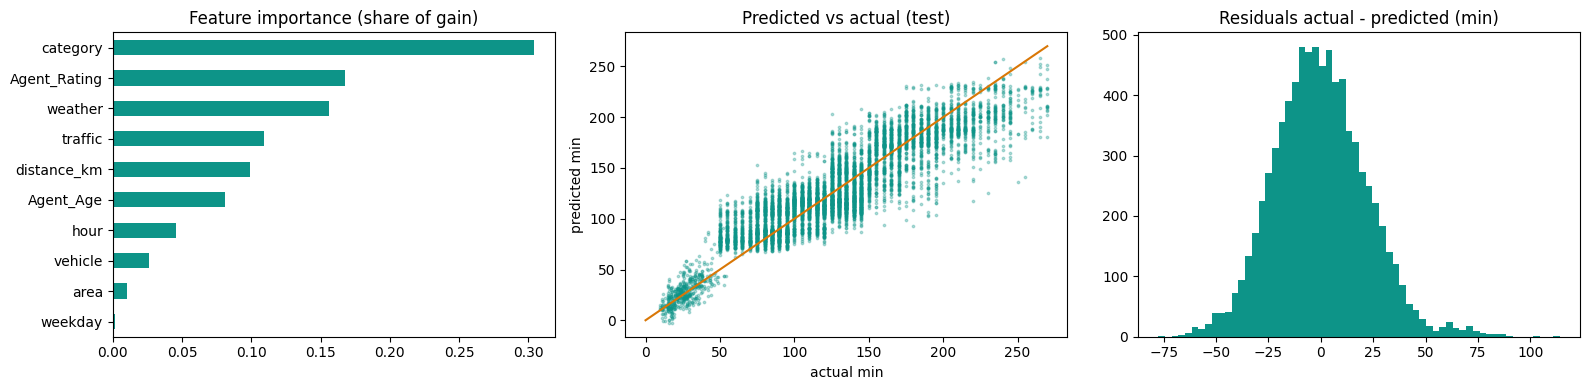

category        0.304
Agent_Rating    0.168
weather         0.156
traffic         0.109
distance_km     0.099
Agent_Age       0.081
hour            0.046
vehicle         0.026
area            0.010
weekday         0.002
dtype: float64

In [7]:
gain = model.feature_importance("gain", iteration=model.best_iteration)
imp = pd.Series(gain / gain.sum(), index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
imp[::-1].plot.barh(ax=ax[0], color="#0d9488", title="Feature importance (share of gain)")
ax[1].scatter(y, pred, s=3, alpha=0.3, color="#0d9488"); ax[1].plot([0, 270], [0, 270], color="#d97706")
ax[1].set(xlabel="actual min", ylabel="predicted min", title="Predicted vs actual (test)")
ax[2].hist(y - pred, bins=60, color="#0d9488"); ax[2].set(title="Residuals actual - predicted (min)")
plt.tight_layout(); plt.show()
imp.round(3)

## 7. Export for the browser (`web/public/data/`) and parity fixtures (`web/tests/fixtures/`)

In [8]:
dump = model.dump_model(num_iteration=model.best_iteration)

def flatten(tree):
    # arrays per tree: f = feature index (-1 = leaf), t = threshold, l/r = child index, v = leaf value,
    # d = 1 if missing goes left. LightGBM rule: go left if x <= threshold.
    f, t, l, r, v, dl = [], [], [], [], [], []
    def walk(n):
        k = len(f); f.append(-1); t.append(0); l.append(-1); r.append(-1); v.append(0); dl.append(0)
        if "leaf_value" in n:
            v[k] = round(n["leaf_value"], 7)
        else:
            assert n["decision_type"] == "<="
            f[k], t[k], dl[k] = n["split_feature"], n["threshold"], int(n["default_left"])
            l[k] = walk(n["left_child"]); r[k] = walk(n["right_child"])
        return k
    walk(tree["tree_structure"])
    return {"f": f, "t": t, "l": l, "r": r, "v": v, "d": dl}

resid_sd = float(np.std(y - pred))
export = {
    "version": "2026-11-15", "model": "LightGBM regression, delivery minutes",
    "features": FEATURES, "traffic": TRAFFIC, "categories": CATS,
    "defaults": {"weekday": 2, "category": int(train.category.mode()[0]),
                 "Agent_Age": float(train.Agent_Age.median()), "Agent_Rating": float(train.Agent_Rating.median())},
    "residual_sd": round(resid_sd, 3),
    "trees": [flatten(t) for t in dump["tree_info"]],
    "dataset_note": "Trained on Kaggle Amazon Delivery Dataset (MIT licence), deliveries in Indian cities, Feb-Apr 2022. Shows the method, not Dubai ground truth.",
}
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "eta_model.json").write_text(json.dumps(export, separators=(",", ":")))

# predicted vs actual sample for the /eta chart (300 seeded test rows)
rng = np.random.default_rng(SEED)
pick = rng.choice(len(test), 300, replace=False)
metrics_out = {
    "mae": round(m["mae"], 2), "rmse": round(m["rmse"], 2), "r2": round(m["r2"], 3),
    "naive_mae": round(nv["mae"], 2), "naive_rmse": round(nv["rmse"], 2), "naive_r2": round(nv["r2"], 3),
    "n_train": int(len(train)), "n_test": int(len(test)), "trees": int(model.best_iteration),
    "split": "chronological: last 20% of orders by date/time are the test set",
    "feature_importance": [{"name": k, "value": round(float(v), 4)} for k, v in imp.items()],
    "pred_vs_actual": [{"actual": int(y[i]), "predicted": round(float(pred[i]), 1)} for i in sorted(pick)],
    "dataset_note": export["dataset_note"],
}
(OUT / "eta_metrics.json").write_text(json.dumps(metrics_out, indent=1))

# 20 test rows with the Python prediction: TypeScript must match within 1e-3
FIX.mkdir(parents=True, exist_ok=True)
rows = test.iloc[:: len(test) // 20][:20]
fx = [{"x": [float(v) for v in r[FEATURES]], "pred": float(p)}
      for (_, r), p in zip(rows.iterrows(), model.predict(rows[FEATURES], num_iteration=model.best_iteration))]
(FIX / "eta_samples.json").write_text(json.dumps({"features": FEATURES, "rows": fx}, indent=1))
for f in ["eta_model.json", "eta_metrics.json"]:
    print(f, round((OUT / f).stat().st_size / 1e6, 3), "MB")

eta_model.json 0.353 MB
eta_metrics.json 0.017 MB


## 8. Pure-Python check of the exported trees (same logic as `eta.ts`)

In [9]:
def predict_json(model_json, x):
    s = 0.0
    for tr in model_json["trees"]:
        k = 0
        while tr["f"][k] >= 0:
            v = x[tr["f"][k]]
            go_left = (tr["d"][k] == 1) if v is None or np.isnan(v) else v <= tr["t"][k]
            k = tr["l"][k] if go_left else tr["r"][k]
        s += tr["v"][k]
    return s

mj = json.loads((OUT / "eta_model.json").read_text())
err = max(abs(predict_json(mj, r["x"]) - r["pred"]) for r in fx)
print("max |json - lightgbm| on fixtures:", err)
assert err < 1e-3

max |json - lightgbm| on fixtures: 9.608941979877272e-07


## 9. What this means for operations
A delivery-time model that beats a distance-only rule lets dispatchers promise tighter, honest ETAs and flag orders likely
to miss their window before the van leaves. In RouteMind it feeds the customer ETA page and live re-routing.
Again: trained on Indian data; a Dubai pilot must retrain on DubaiDash's own delivery logs.